# 02 · Data visualization

This notebook explores the raw dataset visually before model building. It follows the executed audit in `01_data_overview.ipynb`; its figures are descriptive and do not establish performance on news outside this dataset.

## Findings carried forward from Notebook 1

The audit observed 44,898 rows (23,481 fake; 21,417 real), four candidate input fields, no nulls, and 631 blank body-text strings. It found 3 duplicate rows after the first occurrence in `Fake.csv`, 206 in `True.csv`, and no conflicting labels among identical article-field groups. Date parsing succeeded for all 21,417 real records but only 11,868 fake records (50.5%); the parseable range was 2015-05-01 to 2017-12-31. `subject` has only eight distinct values. These metadata patterns may give a classifier shortcuts tied to how the data was assembled.

Macro F1 remains the primary selection metric. Naive Bayes is the model-family constraint; its variant and text representation will be discussed before model building.

## 1. Setup and descriptive fields

Use the shared seed value 42. The plots use a colorblind-friendly blue/vermilion pair consistently. Derived character counts, word counts, and parsed dates are used for descriptive plots only.

In [1]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

GLOBAL_SEED = 42
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)
PALETTE = {'real': '#0072B2', 'fake': '#D55E00'}
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.0)
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 180, 'axes.titleweight': 'bold', 'axes.spines.top': False, 'axes.spines.right': False, 'grid.alpha': 0.22})

here = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [here, *here.parents] if (p / 'data' / 'raw' / 'News').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not locate data/raw/News from the notebook working directory.')
raw_dir = PROJECT_ROOT / 'data' / 'raw' / 'News'
frames = []
for label, filename in [('fake', 'Fake.csv'), ('real', 'True.csv')]:
    frame = pd.read_csv(raw_dir / filename)
    frame['label'] = label
    frame['source_file'] = filename
    frames.append(frame)
news = pd.concat(frames, ignore_index=True)
for col in ['title', 'text']:
    news[f'{col}_chars'] = news[col].fillna('').astype(str).str.len()
    news[f'{col}_words'] = news[col].fillna('').astype(str).str.split().str.len()
news['parsed_date'] = pd.to_datetime(news['date'].astype('string').str.strip(), errors='coerce')
news['date_parseable'] = news['parsed_date'].notna()
print(f'Rows: {len(news):,}; class counts: {news.label.value_counts().to_dict()}')

Rows: 44,898; class counts: {'fake': 23481, 'real': 21417}


## 2. Is the target distribution strongly imbalanced?

Count labels show both absolute support and relative class share. Similar counts do not, on their own, justify resampling.

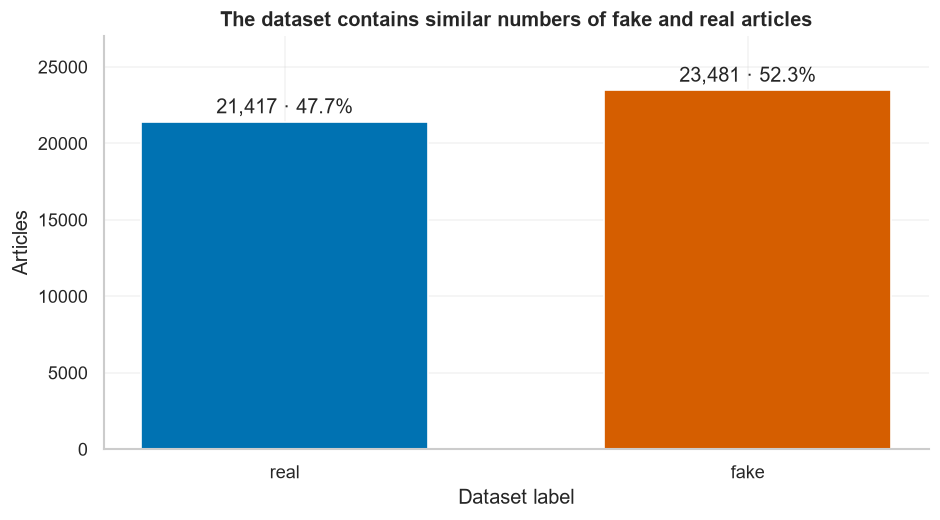

In [2]:
counts = news['label'].value_counts().reindex(['real', 'fake'])
shares = counts / counts.sum() * 100
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(counts.index, counts.values, color=[PALETTE[k] for k in counts.index], width=0.62)
ax.set(title='The dataset contains similar numbers of fake and real articles', ylabel='Articles', xlabel='Dataset label', ylim=(0, counts.max() * 1.15))
for bar, label in zip(bars, counts.index):
    ax.annotate(f'{int(bar.get_height()):,} · {shares[label]:.1f}%', (bar.get_x()+bar.get_width()/2, bar.get_height()), xytext=(0,5), textcoords='offset points', ha='center')
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

## 3. Does `subject` align with the label?

The heatmap shows the fake/real composition within each subject. Row counts give context for each percentage. Strong associations may reflect dataset construction and be a shortcut for a classifier.

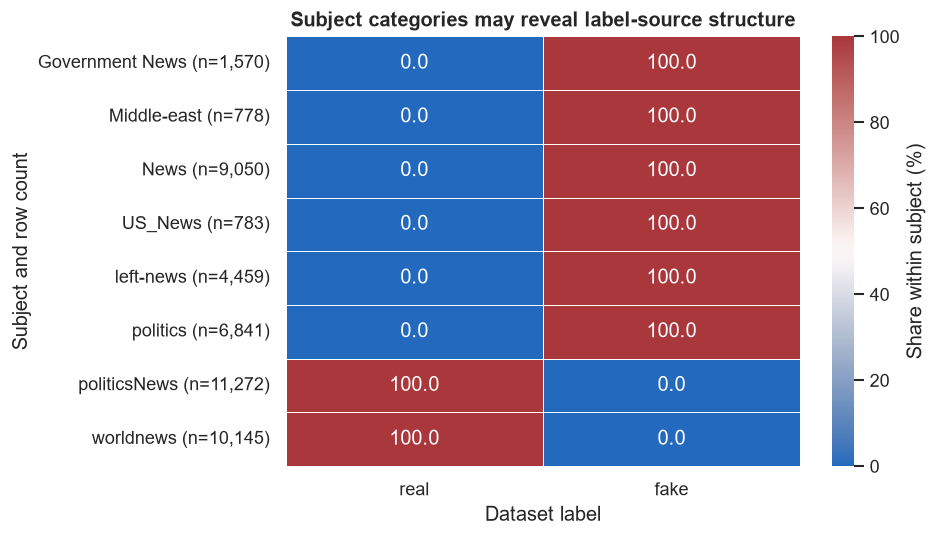

label,real,fake,total
subject,,,
Government News,0,1570,1570
Middle-east,0,778,778
News,0,9050,9050
US_News,0,783,783
left-news,0,4459,4459
politics,0,6841,6841
politicsNews,11272,0,11272
worldnews,10145,0,10145


In [3]:
subject_counts = pd.crosstab(news['subject'].fillna('[missing]'), news['label']).reindex(columns=['real', 'fake'], fill_value=0)
subject_share = subject_counts.div(subject_counts.sum(axis=1), axis=0) * 100
row_labels = [f'{s} (n={int(subject_counts.loc[s].sum()):,})' for s in subject_counts.index]
fig, ax = plt.subplots(figsize=(8, max(4.2, 0.58 * len(subject_counts))))
sns.heatmap(subject_share, annot=True, fmt='.1f', cmap='vlag', center=50, vmin=0, vmax=100, linewidths=0.5, linecolor='white', cbar_kws={'label':'Share within subject (%)'}, ax=ax, yticklabels=row_labels)
ax.set(title='Subject categories may reveal label-source structure', xlabel='Dataset label', ylabel='Subject and row count')
fig.tight_layout()
plt.show()
display(subject_counts.assign(total=subject_counts.sum(axis=1)).rename_axis('subject'))

## 4. How do title and body lengths differ?

Lengths use a `log1p` scale so short and long items remain visible together, including zero-length bodies. Differences may reveal collection or formatting patterns; they do not establish generalizable signal.

In [ ]:
from matplotlib.lines import Line2D
long = news.melt(id_vars='label', value_vars=['title_chars', 'text_chars'], var_name='field', value_name='characters')
long['field'] = long['field'].map({'title_chars':'Title', 'text_chars':'Body text'})
long['log1p_characters'] = np.log1p(long['characters'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, field in zip(axes, ['Title', 'Body text']):
    sns.histplot(data=long[long.field.eq(field)], x='log1p_characters', hue='label', hue_order=['real','fake'], palette=PALETTE, stat='density', common_norm=False, bins=38, element='step', fill=False, linewidth=1.6, ax=ax)
    ax.set(title=f'{field} length', xlabel='log(1 + character count)', ylabel='Density')
    legend_handles = [Line2D([0], [0], color=PALETTE[label], label=label, linewidth=1.6) for label in ['real', 'fake']]
    ax.legend(handles=legend_handles, title='Label', frameon=False)
fig.suptitle('Text length distributions by dataset label', x=0.06, ha='left', y=1.03, fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()
display(news.groupby('label')[['title_chars','text_chars','title_words','text_words']].agg(['median', lambda x: x.quantile(.9)]))
print('Blank body strings:', int(news['text'].fillna('').astype(str).str.strip().eq('').sum()))

## 5. Repeated articles and date coverage

Duplicate counts use the four original article fields and count occurrences after the first within each label. Date parseability is compared by label; monthly counts include only rows with parseable dates and must not be mistaken for complete chronology.

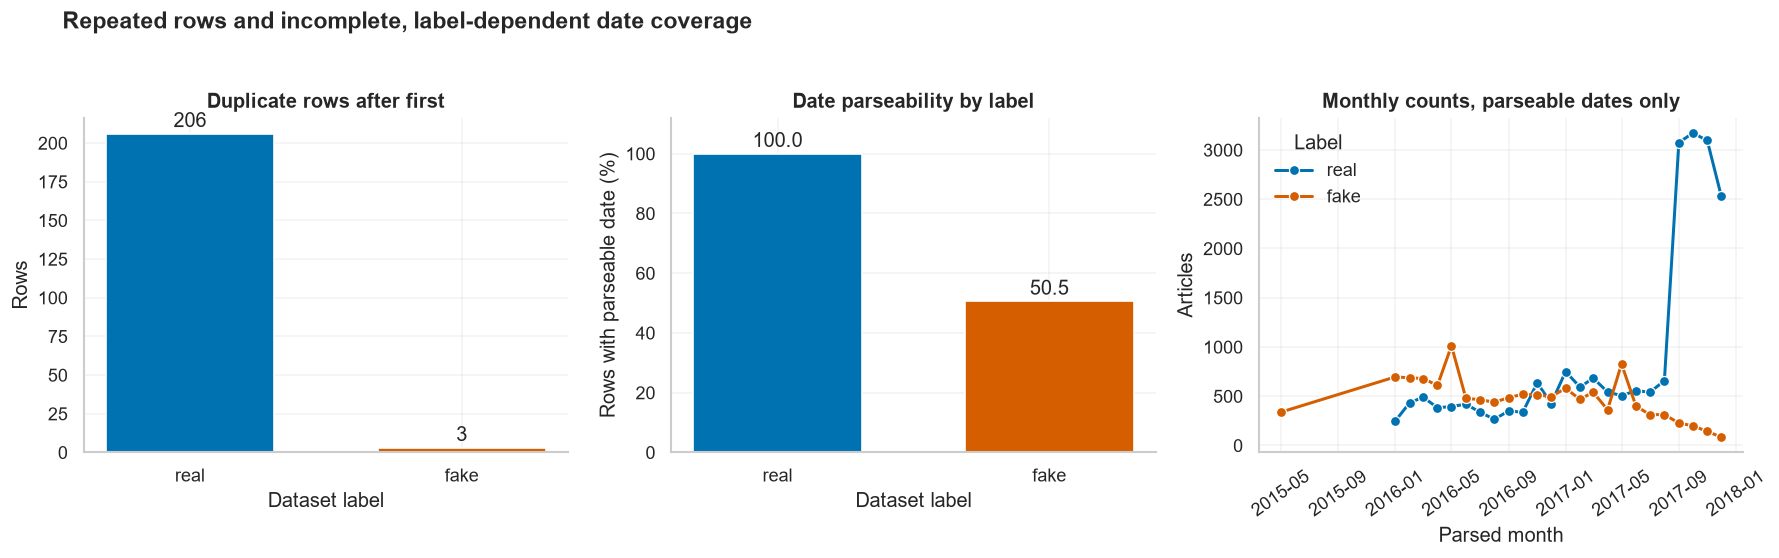

,parseable_rows,total_rows,parseable_fraction
label,,,
real,21417,21417,1.00000
fake,11868,23481,0.50543


Duplicate rows after first occurrence: {'real': 206, 'fake': 3}


In [5]:
article_fields = ['title', 'text', 'subject', 'date']
duplicate_counts = news.groupby('label', group_keys=False).apply(lambda f: int(f.duplicated(subset=article_fields, keep='first').sum()), include_groups=False).reindex(['real','fake'], fill_value=0)
date_quality = news.groupby('label')['date_parseable'].agg(['sum','count','mean']).reindex(['real','fake'])
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, values, title, ylabel in [(axes[0], duplicate_counts, 'Duplicate rows after first', 'Rows'), (axes[1], date_quality['mean']*100, 'Date parseability by label', 'Rows with parseable date (%)')]:
    bars = ax.bar(values.index, values.values, color=[PALETTE[k] for k in values.index], width=.62)
    ax.set(title=title, xlabel='Dataset label', ylabel=ylabel)
    if ylabel.endswith('(%)'): ax.set_ylim(0, 112)
    for bar in bars: ax.annotate(f'{bar.get_height():,.1f}' if ylabel.endswith('(%)') else f'{bar.get_height():,.0f}', (bar.get_x()+bar.get_width()/2, bar.get_height()), xytext=(0,4), textcoords='offset points', ha='center')
monthly = (news.loc[news.date_parseable].assign(month=lambda d: d.parsed_date.dt.to_period('M').dt.to_timestamp()).groupby(['month','label']).size().rename('articles').reset_index())
sns.lineplot(data=monthly, x='month', y='articles', hue='label', hue_order=['real','fake'], palette=PALETTE, marker='o', linewidth=1.8, ax=axes[2])
axes[2].set(title='Monthly counts, parseable dates only', xlabel='Parsed month', ylabel='Articles')
axes[2].tick_params(axis='x', rotation=35)
axes[2].legend(title='Label', frameon=False)
for ax in axes: sns.despine(ax=ax)
fig.suptitle('Repeated rows and incomplete, label-dependent date coverage', x=.04, ha='left', y=1.03, fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()
display(date_quality.rename(columns={'sum':'parseable_rows','count':'total_rows','mean':'parseable_fraction'}))
print('Duplicate rows after first occurrence:', duplicate_counts.to_dict())

## 6. EDA conclusions and modeling implications

- **Class balance:** the dataset has 23,481 fake articles (52.3%) and 21,417 real articles (47.7%); row counts are similar.
- **Subject is completely confounded with the label in these files:** `Government News`, `Middle-east`, `News`, `US_News`, `left-news`, and `politics` occur only with fake labels (23,481 rows total); `politicsNews` and `worldnews` occur only with real labels (21,417 rows total). In this dataset, subject alone separates the labels. This reflects source/collection confounding, not evidence of transferable fake-news cues. Exclude `subject` from a model intended to assess article text, or validation could mostly measure this dataset-specific shortcut.
- **Titles differ visibly:** the fake-labeled title distribution is shifted toward longer titles. Median title length is 90 characters / 14 words for fake versus 64 characters / 10 words for real. Body lengths overlap substantially: median length is 2,166 characters (363 words) for fake versus 2,222 characters (359 words) for real; the 90th percentile body lengths are 4,275 and 4,772 characters, respectively. These remain descriptive associations and may reflect source collections.
- **Blank body text:** 631 records have a blank body string. The figure reports an overall count, not class-specific rates; do not infer which class they belong to from this plot.
- **Duplicate rows:** 206 duplicate rows after the first occurrence are in real-labeled records versus 3 in fake-labeled records. Prevent duplicate articles from crossing training and validation partitions.
- **Date is not a common, reliable timeline as currently parsed:** dates parse for all real rows but only 50.5% of fake rows. Monthly counts among parseable rows also show different coverage patterns, with real-labeled volume concentrated late in 2017 while fake-labeled records have a broader, irregular pattern. Since dates are incomplete and parseability depends on label, do not treat this as a complete chronology or use it for a temporal split without resolving date semantics and missingness.

**Modeling guardrails:** exclude the source filename and subject from text-model inputs; discuss any use of `date` before modeling; account for duplicates in validation; and fit text preprocessing within training folds. Keep claims limited to this sampled dataset.

### Notebook self-critique
These descriptive plots cannot establish that a pattern will generalize, that a publisher is covered, or that an article is factually true. The strongest threat is exact subject/label confounding: a random split could reward source recognition instead of article-content classification. The saved execution of the title/body length figure emitted `No artists with labels found` warnings and did not render class entries in its legend. The plotting cell now constructs explicit legend handles, and its stale warning-bearing output has been cleared so the notebook does not display a figure that disagrees with its corrected code. The figure will be rendered by the next execution of that cell. Date trends are incomplete and label-dependent, so they cannot support a reliable time-based evaluation on their own.